<a href="https://colab.research.google.com/github/Dafwan01/Tugas_P6_Machine_Learning_Daffa_Rizqi_Wandika_232310024/blob/main/Tugas_P6_Machine_Learning_Daffa_Rizqi_Wandika(232310024).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas P6 Machine Learning - Daffa Rizqi Wandika (232310024)

##Inisialisasi

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.cluster import DBSCAN

In [ ]:
url = "https://raw.githubusercontent.com/isnanmulia/lecture-datasets/main/heart_modified.csv"
name = ['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
        'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

dataset = pd.read_csv(url, names=name)

# Buang baris pertama jika ternyata isinya duplikat nama kolom (header dari file csv)
if str(dataset.iloc[0]['Age']) == 'Age':
    dataset = dataset.drop(dataset.index[0]).reset_index(drop=True)

# Kolom numerik dipastikan bertipe angka; nilai yang tidak terbaca menjadi NaN
numeric_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']   # numerik kontinu
binary_cols = ['FastingBS', 'HeartDisease']                               # biner (0/1)
categorical_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in numeric_cols + binary_cols:
    dataset[col] = pd.to_numeric(dataset[col], errors='coerce')

print("Ukuran dataset:", dataset.shape)
print(dataset.head())


Ukuran dataset: (918, 12)
   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA      140.0        289.0          0     Normal  172.0   
1   49   F           NAP      160.0          NaN          0     Normal  156.0   
2   37   M           ATA      130.0        283.0          0         ST   98.0   
3   48   F           ASY      138.0        214.0          0     Normal  108.0   
4   54   M           NAP      150.0        195.0          0     Normal  122.0   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


##Identifikasi nama dan jenis atribut

In [ ]:
for col in dataset.columns:
    unique_vals = dataset[col].dropna().unique()
    num_unique = len(unique_vals)

    if col in numeric_cols:
        attr_type = "Numerik (nilai kontinu/banyak nilai unik)"
    elif col in binary_cols:
        attr_type = "Kategorik biner (0/1)"
    else:
        attr_type = "Kategorik"

    role = "Label (target)" if col == 'HeartDisease' else "Prediktor"

    print(f"Nama Atribut : {col}")
    print(f"Peran        : {role}")
    print(f"Jumlah Unik  : {num_unique}")
    print(f"Jenis Atribut: {attr_type}")
    if col not in numeric_cols:
        print(f"Nilai Unik   : {sorted(unique_vals, key=str)}")
    print("-" * 40)

Nama Atribut : Age
Peran        : Prediktor
Jumlah Unik  : 50
Jenis Atribut: Numerik (nilai kontinu/banyak nilai unik)
----------------------------------------
Nama Atribut : Sex
Peran        : Prediktor
Jumlah Unik  : 2
Jenis Atribut: Kategorik
Nilai Unik   : ['F', 'M']
----------------------------------------
Nama Atribut : ChestPainType
Peran        : Prediktor
Jumlah Unik  : 4
Jenis Atribut: Kategorik
Nilai Unik   : ['ASY', 'ATA', 'NAP', 'TA']
----------------------------------------
Nama Atribut : RestingBP
Peran        : Prediktor
Jumlah Unik  : 67
Jenis Atribut: Numerik (nilai kontinu/banyak nilai unik)
----------------------------------------
Nama Atribut : Cholesterol
Peran        : Prediktor
Jumlah Unik  : 219
Jenis Atribut: Numerik (nilai kontinu/banyak nilai unik)
----------------------------------------
Nama Atribut : FastingBS
Peran        : Prediktor
Jumlah Unik  : 2
Jenis Atribut: Kategorik biner (0/1)
Nilai Unik   : [np.int64(0), np.int64(1)]
--------------------------

## Memisahkan atribut prediktor (X) dan label (y)

In [ ]:
X = dataset.drop(columns=['HeartDisease']).copy()
y = dataset['HeartDisease'].astype(int)

print("Ukuran X:", X.shape, "| Ukuran y:", y.shape)

# Salinan X sebelum praproses, untuk perbandingan statistik di soal 2e
X_before = X.copy()

Ukuran X: (918, 11) | Ukuran y: (918,)


## Melihat missing value dan mengisi

In [ ]:
print("Missing value sebelum imputasi:")
print(X.isna().sum())

imputer_mean = SimpleImputer(strategy='mean')
X[numeric_cols] = imputer_mean.fit_transform(X[numeric_cols])

print("\nMissing value setelah imputasi:")
print(X.isna().sum())

Missing value sebelum imputasi:
Age                0
Sex                0
ChestPainType      0
RestingBP         18
Cholesterol       18
FastingBS          0
RestingECG         0
MaxHR             18
ExerciseAngina     0
Oldpeak            0
ST_Slope           0
dtype: int64

Missing value setelah imputasi:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
dtype: int64


### Menerapkan StandardScaler untuk mengubah nilai atribut prediktor berjenis numerik.

In [ ]:
# FastingBS tidak ikut di-scale karena atributnya biner
X_scaled = X.copy()
scaler = StandardScaler()
X_scaled[numeric_cols] = scaler.fit_transform(X_scaled[numeric_cols])

print(X_scaled.head())

        Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  \
0 -1.433140   M           ATA   0.412038     0.827141          0     Normal   
1 -0.478484   F           NAP   1.497937     0.000000          0     Normal   
2 -1.751359   M           ATA  -0.130911     0.771843          0         ST   
3 -0.584556   F           ASY   0.303448     0.135920          0     Normal   
4  0.051881   M           NAP   0.954988    -0.039190          0     Normal   

      MaxHR ExerciseAngina   Oldpeak ST_Slope  
0  1.388846              N -0.832432       Up  
1  0.756215              N  0.105664     Flat  
2 -1.537075              N -0.832432       Up  
3 -1.141681              Y  0.574711     Flat  
4 -0.588128              N -0.832432       Up  


### Praproses tambahan: One-Hot Encoding atribut kategorik.

In [ ]:
X_encoded = pd.get_dummies(X_scaled, columns=categorical_cols, drop_first=True, dtype=float)
print("Ukuran X setelah One-Hot Encoding:", X_encoded.shape)
print(X_encoded.head())

Ukuran X setelah One-Hot Encoding: (918, 15)
        Age  RestingBP  Cholesterol  FastingBS     MaxHR   Oldpeak  Sex_M  \
0 -1.433140   0.412038     0.827141          0  1.388846 -0.832432    1.0   
1 -0.478484   1.497937     0.000000          0  0.756215  0.105664    0.0   
2 -1.751359  -0.130911     0.771843          0 -1.537075 -0.832432    1.0   
3 -0.584556   0.303448     0.135920          0 -1.141681  0.574711    0.0   
4  0.051881   0.954988    -0.039190          0 -0.588128 -0.832432    1.0   

   ChestPainType_ATA  ChestPainType_NAP  ChestPainType_TA  RestingECG_Normal  \
0                1.0                0.0               0.0                1.0   
1                0.0                1.0               0.0                1.0   
2                1.0                0.0               0.0                0.0   
3                0.0                0.0               0.0                1.0   
4                0.0                1.0               0.0                1.0   

   RestingE

### Statistik dari atribut data sebelum dan setelah dilakukan praproses.

In [ ]:
print("=== STATISTIK DESKRIPTIF SEBELUM PRAPROSES (atribut numerik) ===")
print(X_before[numeric_cols].describe())

print("\n=== STATISTIK DESKRIPTIF SESUDAH PRAPROSES (imputasi mean + StandardScaler) ===")
print(X_scaled[numeric_cols].describe())

=== STATISTIK DESKRIPTIF SEBELUM PRAPROSES (atribut numerik) ===
              Age   RestingBP  Cholesterol       MaxHR     Oldpeak
count  918.000000  900.000000   900.000000  900.000000  918.000000
mean    53.510893  132.411111   199.252222  136.874444    0.887364
std      9.432617   18.611534   109.644221   25.557038    1.066570
min     28.000000    0.000000     0.000000   60.000000   -2.600000
25%     47.000000  120.000000   173.750000  120.000000    0.000000
50%     54.000000  130.000000   223.000000  138.000000    0.600000
75%     60.000000  140.000000   267.250000  156.000000    1.500000
max     77.000000  200.000000   603.000000  202.000000    6.200000

=== STATISTIK DESKRIPTIF SESUDAH PRAPROSES (imputasi mean + StandardScaler) ===
                Age     RestingBP   Cholesterol         MaxHR       Oldpeak
count  9.180000e+02  9.180000e+02  9.180000e+02  9.180000e+02  9.180000e+02
mean  -1.083616e-16  7.275710e-16 -3.096047e-17 -7.894919e-16  1.238419e-16
std    1.000545e+00  1.

## klasifikasi menggunakan Decision Tree dan Metode Holdout 85:15.

Ukuran X_train: (780, 15)
Ukuran X_test : (138, 15)

Akurasi Decision Tree: 0.7971 (79.71%)

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78        62
           1       0.84      0.78      0.81        76

    accuracy                           0.80       138
   macro avg       0.80      0.80      0.80       138
weighted avg       0.80      0.80      0.80       138



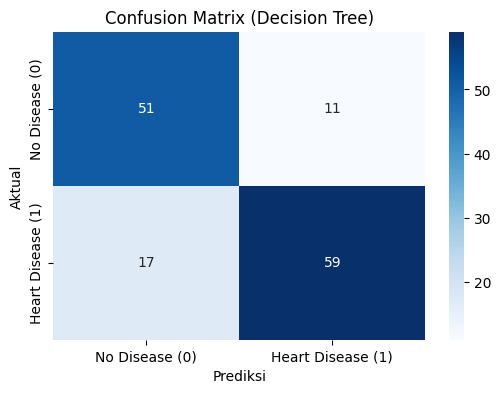

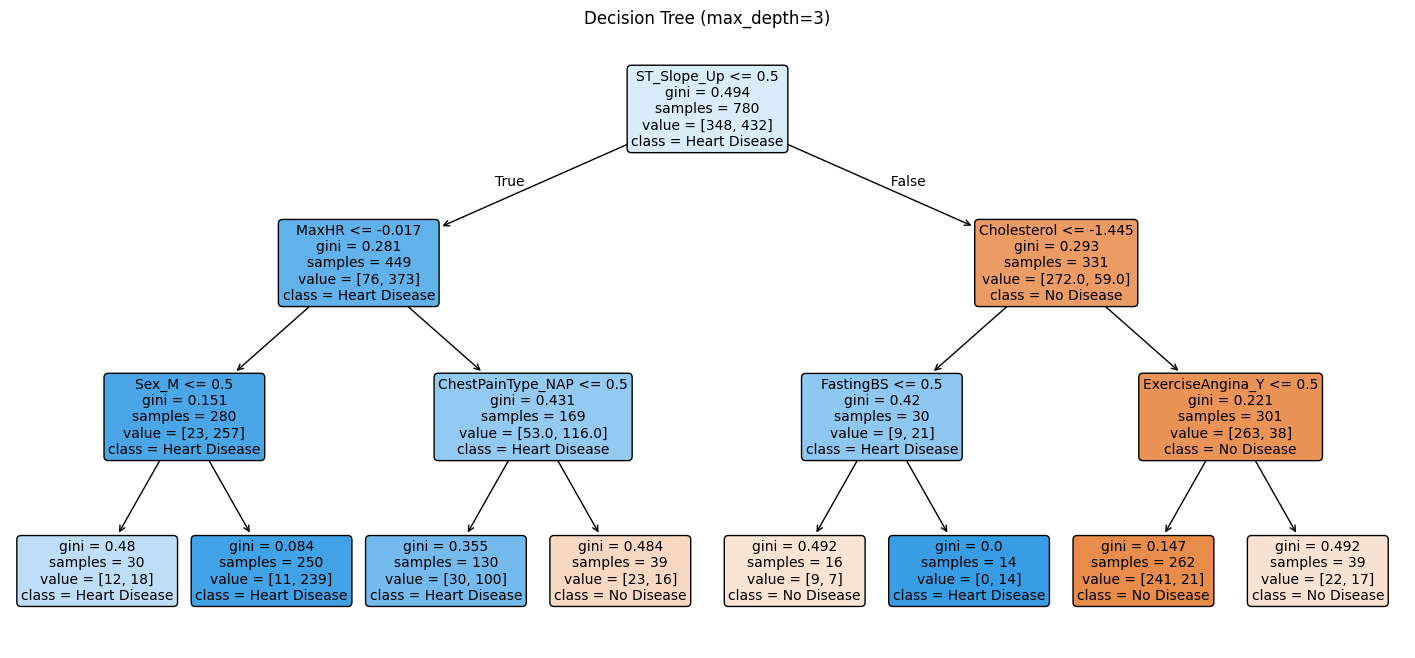

In [ ]:
#Holdout 85% training : 15% testing
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.15, random_state=42, stratify=y
)
print(f"Ukuran X_train: {X_train.shape}\nUkuran X_test : {X_test.shape}")

# Decision Tree
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

#  Evaluasi
akurasi = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\nAkurasi Decision Tree: {akurasi:.4f} ({akurasi * 100:.2f}%)\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease (0)', 'Heart Disease (1)'],
            yticklabels=['No Disease (0)', 'Heart Disease (1)'])
plt.title('Confusion Matrix (Decision Tree)')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

# Visualisasi pohon
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=X_train.columns,
          class_names=['No Disease', 'Heart Disease'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (max_depth=3)')
plt.show()

## Clustering DBSCAN(testing)

Kombinasi parameter yang valid (eps, min_samples, klaster, noise, silhouette):
eps=1.5, min_samples=3, klaster=7, noise=248, silhouette=-0.0977
eps=1.5, min_samples=8, klaster=3, noise=381, silhouette=-0.0239
eps=1.5, min_samples=10, klaster=2, noise=438, silhouette=0.1806
eps=1.6, min_samples=3, klaster=8, noise=177, silhouette=-0.0850
eps=1.7000000000000002, min_samples=3, klaster=7, noise=125, silhouette=-0.0683

Parameter terpilih: eps=1.5, min_samples=10
Jumlah klaster yang terbentuk: 2
Jumlah noise (pencilan)      : 438
Silhouette Score: 0.1806
SSE             : 2269.8575


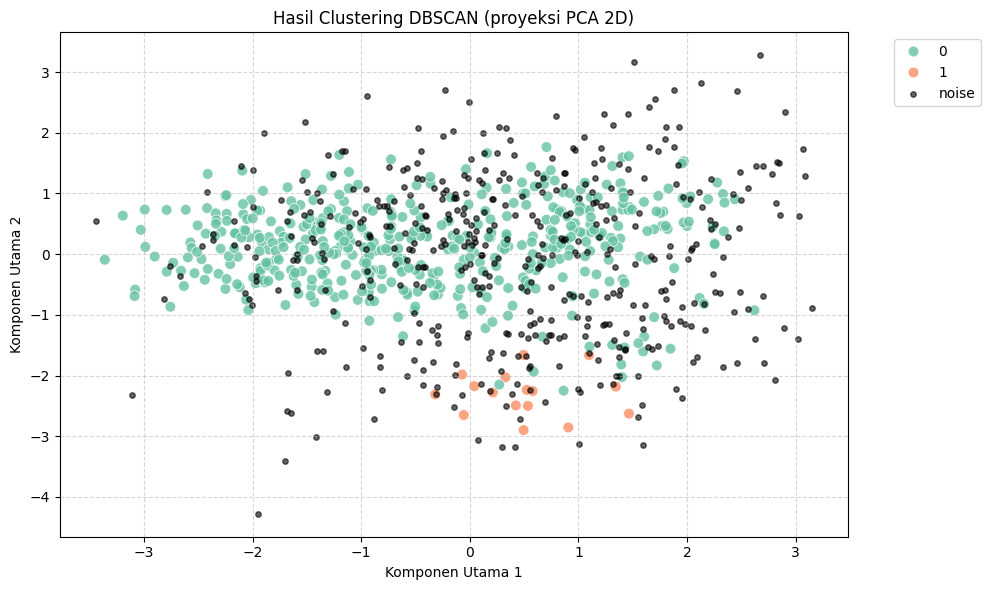

In [ ]:
X_arr = X_encoded.values

# Fungsi SSE: jumlah kuadrat jarak titik ke pusat klaster masing-masing (noise tidak dihitung)
def hitung_sse(X, labels):
    sse = 0.0
    for lab in set(labels) - {-1}:
        pts = X[labels == lab]
        sse += np.sum((pts - pts.mean(axis=0)) ** 2)
    return sse

# Coba beberapa kombinasi parameter, simpan yang valid
hasil = []
for eps in np.arange(1.5, 3.1, 0.1):
    for ms in [3, 5, 8, 10, 15]:
        lab = DBSCAN(eps=round(eps, 1), min_samples=ms).fit_predict(X_arr)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        n_noise = int(np.sum(lab == -1))
        if n_cl >= 2 and n_noise <= 0.5 * len(lab):
            mask = lab != -1
            sil = silhouette_score(X_arr[mask], lab[mask])
            hasil.append((eps, ms, n_cl, n_noise, sil))

print("Kombinasi parameter yang valid (eps, min_samples, klaster, noise, silhouette):")
for h in hasil:
    print(f"eps={h[0]}, min_samples={h[1]}, klaster={h[2]}, noise={h[3]}, silhouette={h[4]:.4f}")

# Pilih silhouette tertinggi; jika tidak ada yang valid, pakai parameter cadangan
if hasil:
    best = max(hasil, key=lambda h: h[4])
    best_eps, best_ms = best[0], best[1]
else:
    best_eps, best_ms = 2.5, 5
    print("Tidak ada kombinasi yang memenuhi syarat, memakai parameter cadangan.")

print(f"\nParameter terpilih: eps={best_eps}, min_samples={best_ms}")

# Clustering final
db_labels = DBSCAN(eps=best_eps, min_samples=best_ms).fit_predict(X_arr)
n_clusters_ = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_ = int(np.sum(db_labels == -1))

print(f"Jumlah klaster yang terbentuk: {n_clusters_}")
print(f"Jumlah noise (pencilan)      : {n_noise_}")

#  Evaluasi (titik noise tidak ikut dihitung)
mask = db_labels != -1
if n_clusters_ >= 2:
    print(f"Silhouette Score: {silhouette_score(X_arr[mask], db_labels[mask]):.4f}")
else:
    print("Silhouette Score tidak dapat dihitung karena klaster kurang dari 2.")

if n_clusters_ >= 1:
    print(f"SSE             : {hitung_sse(X_arr, db_labels):.4f}")

# Visualisasi dengan PCA 2D
X_pca = PCA(n_components=2).fit_transform(X_arr)
df_vis = pd.DataFrame(X_pca, columns=['Komponen PCA 1', 'Komponen PCA 2'])
df_vis['Cluster'] = db_labels

klaster_df = df_vis[df_vis['Cluster'] != -1]
noise_df = df_vis[df_vis['Cluster'] == -1]

plt.figure(figsize=(10, 6))
sns.scatterplot(x='Komponen PCA 1', y='Komponen PCA 2', data=klaster_df,
                hue='Cluster', palette='Set2', legend='full', s=60, alpha=0.8)
plt.scatter(noise_df['Komponen PCA 1'], noise_df['Komponen PCA 2'],
            s=15, color='black', label='noise', alpha=0.6)
plt.title('Hasil Clustering DBSCAN (proyeksi PCA 2D)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## clustering dengan AgglomerativeClustering

k=2, SSE=5181.3791, silhouette=0.1636
k=3, SSE=4459.4232, silhouette=0.1904
k=4, SSE=4240.4758, silhouette=0.1379
k=5, SSE=4056.5083, silhouette=0.0936
k=6, SSE=3931.2025, silhouette=0.0891
k=7, SSE=3813.0863, silhouette=0.0817
k=8, SSE=3715.5657, silhouette=0.0775


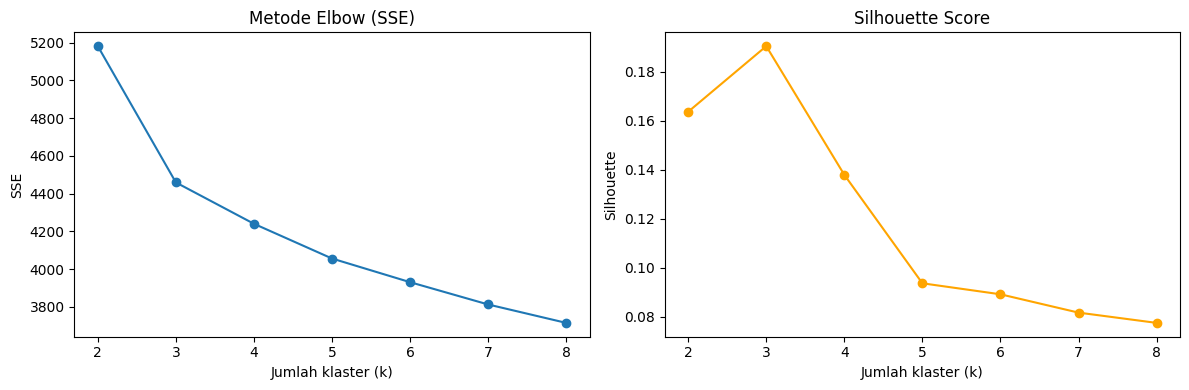


k terpilih      : 3
SSE             : 4459.4232
Silhouette Score: 0.1904
Jumlah data per klaster: [371 377 170]


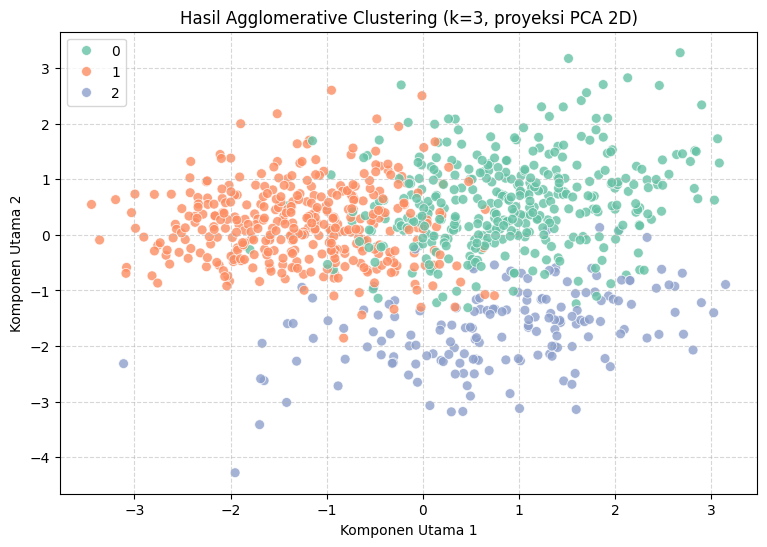

In [ ]:
import numpy as np
import pandas as pd

X_arr = X_encoded.values

# SSE: jumlah kuadrat jarak titik ke pusat (rata-rata) klaster masing-masing
def hitung_sse(X, labels):
    sse = 0.0
    for lab in np.unique(labels):
        pts = X[labels == lab]
        sse += np.sum((pts - pts.mean(axis=0)) ** 2)
    return sse

# Coba k = 2 sampai 8
k_range = range(2, 9)
sse_list, sil_list = [], []
for k in k_range:
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_arr)
    sse_list.append(hitung_sse(X_arr, lab))
    sil_list.append(silhouette_score(X_arr, lab))
    print(f"k={k}, SSE={sse_list[-1]:.4f}, silhouette={sil_list[-1]:.4f}")

# Grafik elbow dan silhouette
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_range), sse_list, marker='o')
ax[0].set_title('Metode Elbow (SSE)')
ax[0].set_xlabel('Jumlah klaster (k)')
ax[0].set_ylabel('SSE')
ax[1].plot(list(k_range), sil_list, marker='o', color='orange')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Jumlah klaster (k)')
ax[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

# Model final: k dengan silhouette tertinggi
best_k = list(k_range)[int(np.argmax(sil_list))]
labels = AgglomerativeClustering(n_clusters=best_k, linkage='ward').fit_predict(X_arr)

print(f"\nk terpilih      : {best_k}")
print(f"SSE             : {hitung_sse(X_arr, labels):.4f}")
print(f"Silhouette Score: {silhouette_score(X_arr, labels):.4f}")
print("Jumlah data per klaster:", np.bincount(labels))

# Visualisasi PCA 2D
X_pca = PCA(n_components=2).fit_transform(X_arr)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels,
                palette='Set2', s=50, alpha=0.8)
plt.title(f'Hasil Agglomerative Clustering (k={best_k}, proyeksi PCA 2D)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# Gunakan X (hasil imputasi, belum di-scale) dan labels dari model k=3
profil = X.copy()
profil['Klaster'] = labels
profil['HeartDisease'] = y.values

# 1. Jumlah data per klaster
print(profil['Klaster'].value_counts().sort_index())

# 2. Rata-rata atribut numerik per klaster
print("\nRata-rata atribut numerik:")
print(profil.groupby('Klaster')[numeric_cols + ['FastingBS']].mean().round(2))

# 3. Persentase penyakit jantung per klaster
print("\nPersentase HeartDisease=1 per klaster (%):")
print((profil.groupby('Klaster')['HeartDisease'].mean() * 100).round(1))

# 4. Persentase kategori di tiap atribut kategorik
for col in categorical_cols:
    print(f"\n{col} (% per klaster):")
    print((pd.crosstab(profil['Klaster'], profil[col], normalize='index') * 100).round(1))

Klaster
0    371
1    377
2    170
Name: count, dtype: int64

Rata-rata atribut numerik:
           Age  RestingBP  Cholesterol   MaxHR  Oldpeak  FastingBS
Klaster                                                           
0        57.37     137.32       247.36  127.57     1.62       0.23
1        48.51     128.86       241.27  152.63     0.20       0.11
2        56.18     129.57         1.09  122.25     0.81       0.51

Persentase HeartDisease=1 per klaster (%):
Klaster
0    79.5
1    17.0
2    87.6
Name: HeartDisease, dtype: float64

Sex (% per klaster):
Sex         F     M
Klaster            
0        17.5  82.5
1        31.3  68.7
2         5.9  94.1

ChestPainType (% per klaster):
ChestPainType   ASY   ATA   NAP   TA
Klaster                             
0              70.6   6.5  16.4  6.5
1              29.2  37.4  28.9  4.5
2              72.9   4.7  19.4  2.9

RestingECG (% per klaster):
RestingECG   LVH  Normal    ST
Klaster                       
0           28.0    49.6  22.